# Preliminary data analysis

Before building the model: is the data trustworthy, and do the assumptions behind
the features hold? Plots and simple numbers only, no modelling.
Each chart is followed by one sentence on what it shows.

Data: `electricity_prices.db` (built by `BuildDB_v2.py`). Prices in Rp./kWh.
Plan: `ML_CONCEPT.md`.

| # | Question |
|---|---|
| 0 | Is the local-time grid complete (24 hours per day)? |
| 1 | What does the target look like, and how extreme does it get? |
| 2 | How stable is the daily shape across seasons and weekends? |
| 3 | How closely does CH follow DE? |
| 4 | Is wind a strong driver of the charging-window price? |
| 5 | Do solar and temperature show the expected effects? |
| 6 | How much does forecast quality drop with lead time? |
| 7 | Where are the savings: choosing the right night or the right hours? |
| 8 | How good are the simple rules the model has to beat? |

In [1]:
# Libraries: sqlite3 reads the database, matplotlib draws the charts,
# numpy and pandas do the calculations
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Settings
DATABASE = "electricity_prices.db"
START = "2024-03-09"            # first day with complete weather forecasts (see ML_CONCEPT.md)

# Colours: fixed order, one colour per entity, the same in every chart
BLUE, ORANGE, AQUA, YELLOW = "#257de0", "#f47230", "#00b894", "#f2a600"
SEASON_COLOURS = {"Winter": BLUE, "Spring": AQUA, "Summer": YELLOW, "Autumn": ORANGE}
GREY = "#666666"

# One chart style for the whole notebook: no top/right frame, light grid, grey axes
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.5, "axes.titlesize": 11, "axes.titleweight": "bold",
})

Matplotlib is building the font cache; this may take a moment.


## 0 · Load the data and build the local-time grid

`ml_data` has one row per UTC hour. The model works on delivery days in Swiss time,
hours 0–23. The pivot averages the two 02:00 hours of the 25-hour day (October);
the missing 02:00 of the 23-hour day (March) is interpolated.

In [2]:
# Read the three tables we need from the database into DataFrames
with sqlite3.connect(DATABASE) as connection:
    data = pd.read_sql("SELECT * FROM ml_data", connection)
    prices_de = pd.read_sql("SELECT * FROM prices_de", connection)
    vehicles = pd.read_sql("SELECT * FROM vehicles", connection)

# German prices only have UTC times: derive Swiss local time the same way
prices_de["time_local"] = (pd.to_datetime(prices_de["time_utc"], utc=True)
                           .dt.tz_convert("Europe/Zurich").dt.tz_localize(None))

# Add the local calendar day and hour (0-23) to both tables; the grid is built on these
for frame in (data, prices_de):
    frame["time_local"] = pd.to_datetime(frame["time_local"])
    frame["date"] = frame["time_local"].dt.normalize()
    frame["hour"] = frame["time_local"].dt.hour
# Keep only days from START on (before that the weather forecasts are incomplete)
data = data[data["date"] >= START].copy()
prices_de = prices_de[prices_de["date"] >= START]


def to_grid(frame, column):
    """One row per local date, one column per hour 0-23 (DST days fixed)."""
    grid = frame.pivot_table(index="date", columns="hour", values=column, aggfunc="mean")
    return grid.interpolate(axis=1, limit=1, limit_area="inside")


# Price grids: one row per day, one column per hour
price_ch = to_grid(data, "price_rp_kwh").dropna(how="all")   # future days have no price yet
price_de = to_grid(prices_de, "price_rp_kwh")

# Quality check: rows per day. Normal days have 24, clock-change days 23 or 25
hours_per_day = data.groupby("date").size()
print(f"Days with prices: {len(price_ch)}  ({price_ch.index.min():%Y-%m-%d} to {price_ch.index.max():%Y-%m-%d})")
print(f"Hour columns: {price_ch.shape[1]}, empty cells: {int(price_ch.isna().sum().sum())}")
print("Days with 23 or 25 rows in ml_data (clock change):",
      ", ".join(f"{d:%Y-%m-%d} ({n})" for d, n in hours_per_day[hours_per_day != 24].items()))

Days with prices: 995  (2024-03-09 to 2026-11-28)
Hour columns: 24, empty cells: 0
Days with 23 or 25 rows in ml_data (clock change): 2024-03-31 (23), 2024-10-27 (25), 2025-03-30 (23), 2025-10-26 (25), 2026-03-29 (23), 2026-10-25 (25)


## 1 · The target: Swiss day-ahead price

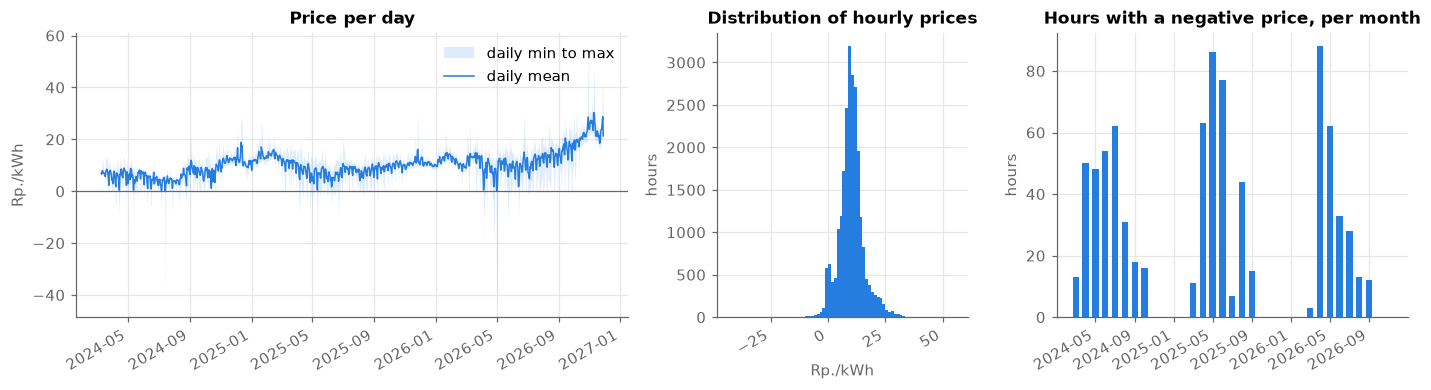

count    23880.00
mean        10.10
std          5.55
min        -43.59
1%          -1.74
5%           0.50
50%          9.97
95%         20.17
99%         26.50
max         56.09
Negative hours: 834 (3.5%)


In [3]:
# Daily mean price, and all hourly prices as one long series
daily = price_ch.mean(axis=1)
hourly = price_ch.stack()

# Three charts side by side: price over time, distribution, negative hours per month
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1.4]})

# Left: band from the daily minimum to the maximum, line = daily mean
axes[0].fill_between(price_ch.index, price_ch.min(axis=1), price_ch.max(axis=1),
                     color=BLUE, alpha=0.15, linewidth=0, label="daily min to max")
axes[0].plot(daily.index, daily, color=BLUE, linewidth=1, label="daily mean")
axes[0].axhline(0, color=GREY, linewidth=0.8)
axes[0].set(title="Price per day", ylabel="Rp./kWh")
axes[0].legend(frameon=False, loc="upper right")

# Middle: histogram of all hourly prices
axes[1].hist(hourly, bins=80, color=BLUE)
axes[1].set(title="Distribution of hourly prices", xlabel="Rp./kWh", ylabel="hours")

# Right: number of hours with a negative price, summed per month
negative = (price_ch < 0).sum(axis=1).groupby(price_ch.index.to_period("M")).sum()
axes[2].bar(negative.index.to_timestamp(), negative, width=20, color=BLUE)
axes[2].set(title="Hours with a negative price, per month", ylabel="hours")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Key numbers of the hourly prices (the percentiles show how extreme it gets)
print(hourly.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())
print(f"Negative hours: {(hourly < 0).sum()} ({(hourly < 0).mean():.1%})")

**Finding:** Hourly prices mostly lie between 0.5 and 20 Rp./kWh (5 % to 95 %), with 834 negative hours (3.5 %), all between March and October (solar surplus), none in winter. Since September 2026 the level climbs steeply (monthly mean 24.2 Rp./kWh in November 2026 vs. about 10 before), so the hold-out lies partly at a level never seen in training; this is why the model predicts the change vs. the known day, not the price itself.

## 2 · Daily shape by month and day type

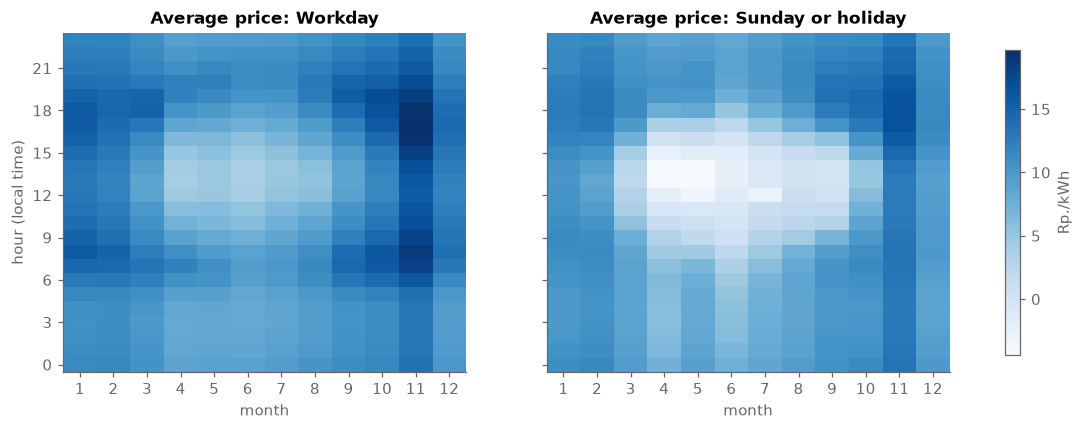

Average price by day type (Rp./kWh): {'Saturday': 8.79, 'Sunday or holiday': 7.64, 'Workday': 10.97}


In [4]:
# Day type of every day: Sunday/holiday, Saturday or workday
holiday = data.groupby("date")["holiday_ch"].max()
weekday = price_ch.index.dayofweek
day_type = pd.Series(np.where((weekday == 6) | (holiday.reindex(price_ch.index) == 1), "Sunday or holiday",
                     np.where(weekday == 5, "Saturday", "Workday")), index=price_ch.index)

# Average price per (month, hour), separately for workdays and Sundays/holidays
panels = ["Workday", "Sunday or holiday"]
profiles = {t: price_ch[day_type == t].groupby(price_ch.index[day_type == t].month).mean() for t in panels}
# Same colour scale in both heatmaps, so that they can be compared directly
low = min(p.min().min() for p in profiles.values())
high = max(p.max().max() for p in profiles.values())

# Heatmaps: x = month, y = hour of day, colour = average price
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, t in zip(axes, panels):
    image = ax.imshow(profiles[t].T, aspect="auto", origin="lower", cmap="Blues", vmin=low, vmax=high,
                      extent=[0.5, 12.5, -0.5, 23.5])
    ax.set(title=f"Average price: {t}", xlabel="month", xticks=range(1, 13))
    ax.grid(False)
axes[0].set(ylabel="hour (local time)", yticks=range(0, 24, 3))
fig.colorbar(image, ax=axes, label="Rp./kWh", shrink=0.9)
plt.show()

# Average price per day type
shape = price_ch.groupby(day_type).mean()
print("Average price by day type (Rp./kWh):", shape.mean(axis=1).round(2).to_dict())

**Finding:** Workdays show a morning (7–9 h) and an evening (17–20 h) peak; from spring to autumn a deep midday dip appears, strongest on Sundays and holidays where it falls below zero in April to July. Sundays/holidays are about 3.3 Rp./kWh cheaper than workdays (7.6 vs. 11.0), so `hour`, `day_type` and hour × solar belong in the model.

## 3 · How closely does CH follow DE?

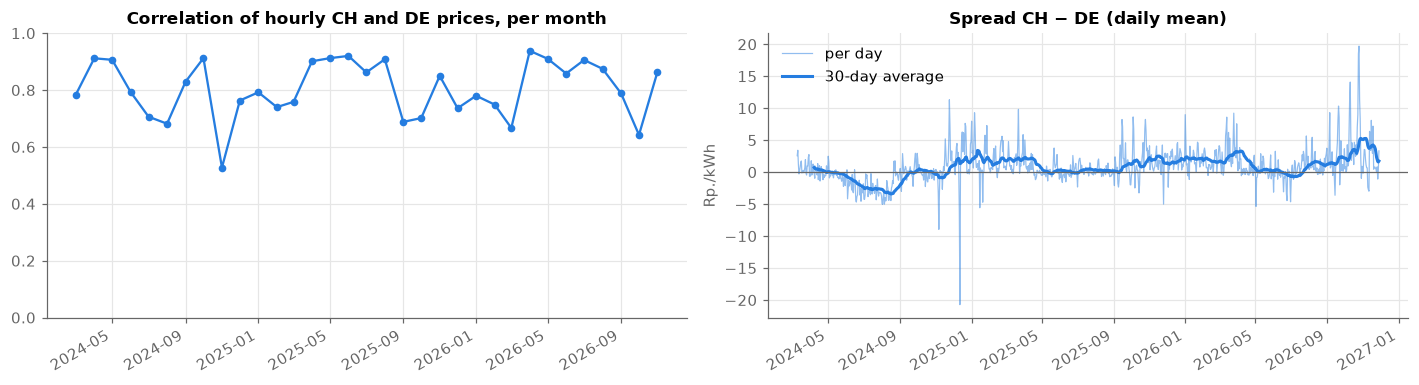

Correlation over all hours: 0.81
Lowest month: 2024-11 (0.53)
Average spread CH − DE: 0.85 Rp./kWh


In [5]:
# CH and DE price of every hour side by side (only hours where both exist)
both = pd.DataFrame({"ch": price_ch.stack(), "de": price_de.stack()}).dropna()
# Correlation between CH and DE, calculated separately for every month
month = both.index.get_level_values(0).to_period("M")
correlation = both.groupby(month).apply(lambda m: m["ch"].corr(m["de"]))
# Spread: how much more expensive CH is than DE, per day
spread = (price_ch.mean(axis=1) - price_de.mean(axis=1)).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(correlation.index.to_timestamp(), correlation, color=BLUE, marker="o", markersize=4)
axes[0].set(title="Correlation of hourly CH and DE prices, per month", ylim=(0, 1))
axes[1].plot(spread.index, spread, color=BLUE, linewidth=0.8, alpha=0.5, label="per day")
# The 30-day rolling average smooths out the daily noise
axes[1].plot(spread.rolling(30).mean().index, spread.rolling(30).mean(), color=BLUE, linewidth=2,
             label="30-day average")
axes[1].axhline(0, color=GREY, linewidth=0.8)
axes[1].set(title="Spread CH − DE (daily mean)", ylabel="Rp./kWh")
axes[1].legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"Correlation over all hours: {both['ch'].corr(both['de']):.2f}")
print(f"Lowest month: {correlation.idxmin()} ({correlation.min():.2f})")
print(f"Average spread CH − DE: {spread.mean():.2f} Rp./kWh")

**Finding:** CH follows DE closely (correlation 0.81 over all hours, mostly 0.7–0.9 per month), but decouples in some months (lowest November 2024: 0.53). CH is on average 0.85 Rp./kWh above DE, and the gap widened to about +5 in autumn 2026, so `de_spread` adds information but DE alone is not enough.

## 4 · Wind and the price in the charging window

One "night" = the depot hours of the whole fleet, from the earliest arrival in the
evening to the latest departure the next morning (read from the `vehicles` table,
sample fleet: 16:00–08:00). Wind is the forecast made two days ahead (`_fc_d2`), the
same one the model will see, converted to the wind proxy `wind_cf` from
`ML_CONCEPT.md`. For this chart the three locations are averaged; the model gets
them as separate columns.

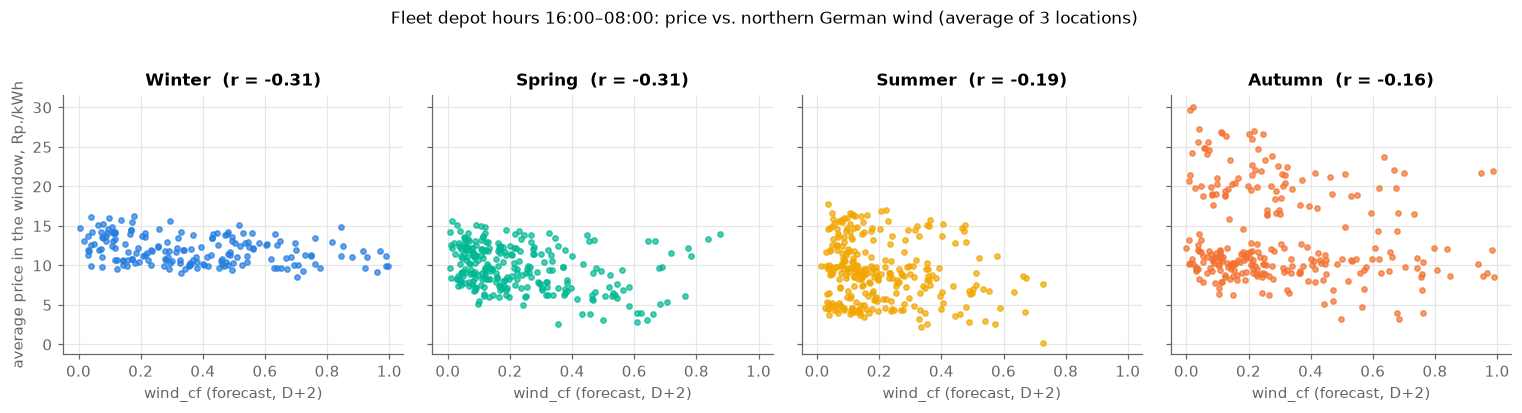

Nights: 994, correlation over all: -0.08


In [6]:
def wind_cf(speed):
    """Wind speed (m/s) -> rough share of wind-turbine capacity (0-1)."""
    share = np.minimum(speed, 12) ** 3 / 12 ** 3
    return np.where((speed < 3) | (speed > 25), 0, share)


# Weather proxies from the forecast made 2 days ahead (the same one the model sees)
# Wind: average capacity share of the three northern German locations
wind_columns = ["wind_de_hamburg", "wind_de_husum", "wind_de_emden"]
data["wind_cf_d2"] = np.mean([wind_cf(data[f"{c}_fc_d2"]) for c in wind_columns], axis=0)
# Solar: radiation / 1000 W/m² -> rough share of solar capacity (max. 1)
data["solar_cf_de_d2"] = np.minimum(data["solar_de_fc_d2"] / 1000, 1)
data["solar_cf_ch_d2"] = np.minimum(data["solar_fc_d2"] / 1000, 1)
# Heating degrees: how far the average CH/DE temperature is below 15 °C
data["hdd_d2"] = np.maximum(0, 15 - (data["temperature_fc_d2"] + data["temperature_de_fc_d2"]) / 2)

# Month -> season (used for the colours)
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}

# Depot hours of the whole fleet: from the earliest arrival to the latest departure
arrival = vehicles["depot_arrival"].str[:2].astype(int).min()
departure = vehicles["depot_departure"].str[:2].astype(int).max()
# True for hours in the evening (from arrival) or in the morning (before departure)
in_depot = (data["hour"] >= arrival) | (data["hour"] < departure)
nights = data[in_depot & data["price_rp_kwh"].notna()].copy()
# Morning hours belong to the night that started the evening before
nights["night"] = (nights["time_local"] - pd.Timedelta(hours=departure)).dt.normalize()
# One row per night: average price, average wind, number of hours
per_night = nights.groupby("night").agg(price=("price_rp_kwh", "mean"), wind=("wind_cf_d2", "mean"),
                                        hours=("price_rp_kwh", "size"))
# Drop incomplete nights (fewer than 12 hours with a price)
per_night = per_night[per_night["hours"] >= 12].dropna()
per_night["season"] = per_night.index.month.map(SEASONS)

# One scatter plot per season: wind (x) vs. price in the charging window (y)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, (season, colour) in zip(axes, SEASON_COLOURS.items()):
    part = per_night[per_night["season"] == season]
    ax.scatter(part["wind"], part["price"], s=12, color=colour, alpha=0.7)
    ax.set(title=f"{season}  (r = {part['wind'].corr(part['price']):.2f})", xlabel="wind_cf (forecast, D+2)")
axes[0].set_ylabel("average price in the window, Rp./kWh")
plt.suptitle(f"Fleet depot hours {arrival}:00–{departure:02d}:00: price vs. northern German wind (average of 3 locations)",
             y=1.03, fontsize=11)
plt.tight_layout()
plt.show()

print(f"Nights: {len(per_night)}, correlation over all: {per_night['wind'].corr(per_night['price']):.2f}")

The price **level** moves a lot over the year (gas prices, season), which hides the
wind effect above. The model predicts the **change** compared with the known day
(`ML_CONCEPT.md`, Step 3), so the relevant question is: if the next night is windier
than this one, is it also cheaper?

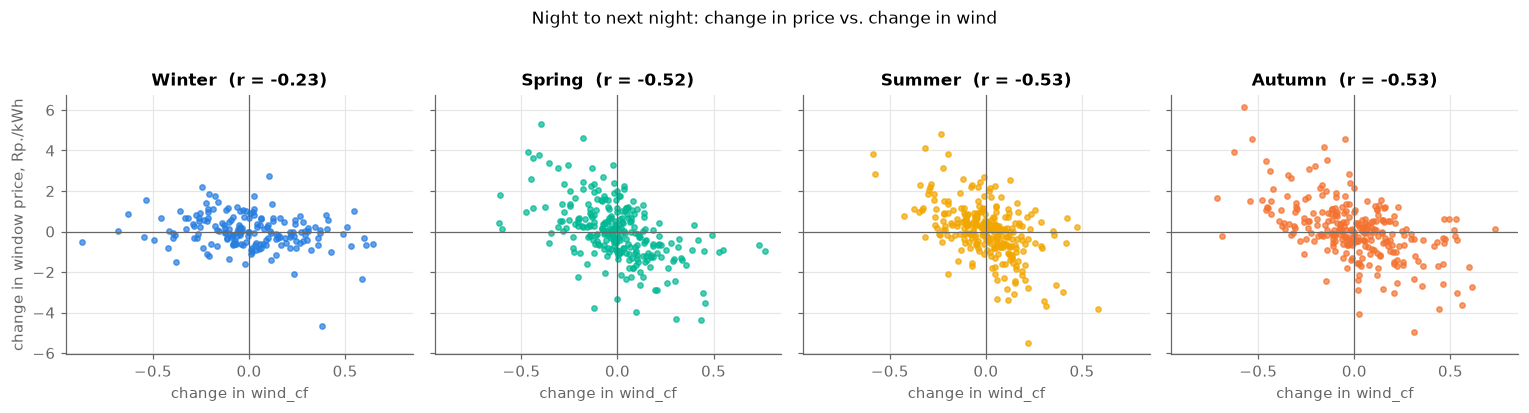

Correlation of the changes over all nights: -0.47


In [7]:
# Only compare nights that directly follow each other (no gap in the data)
consecutive = per_night.index.to_series().diff() == pd.Timedelta(days=1)
# diff(): change from one night to the next, for price and wind
change = per_night[["price", "wind"]].diff()[consecutive]
change["season"] = per_night["season"][consecutive]

# One scatter plot per season: change in wind (x) vs. change in price (y)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, (season, colour) in zip(axes, SEASON_COLOURS.items()):
    part = change[change["season"] == season]
    ax.scatter(part["wind"], part["price"], s=12, color=colour, alpha=0.7)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.set(title=f"{season}  (r = {part['wind'].corr(part['price']):.2f})", xlabel="change in wind_cf")
axes[0].set_ylabel("change in window price, Rp./kWh")
plt.suptitle("Night to next night: change in price vs. change in wind", y=1.03, fontsize=11)
plt.tight_layout()
plt.show()

print(f"Correlation of the changes over all nights: {change['wind'].corr(change['price']):.2f}")

**Finding:** On the price *level*, wind looks like a weak driver (r = −0.08 over all nights): the level is dominated by slower factors such as season and fuel prices. On *changes* the effect is clear: if the next night is windier, it is cheaper (r = −0.47 over all nights, about −0.52 from spring to autumn, only −0.23 in winter). This supports predicting changes vs. the known day, with `d_*` wind features.

## 5 · Solar at midday, temperature in winter evenings

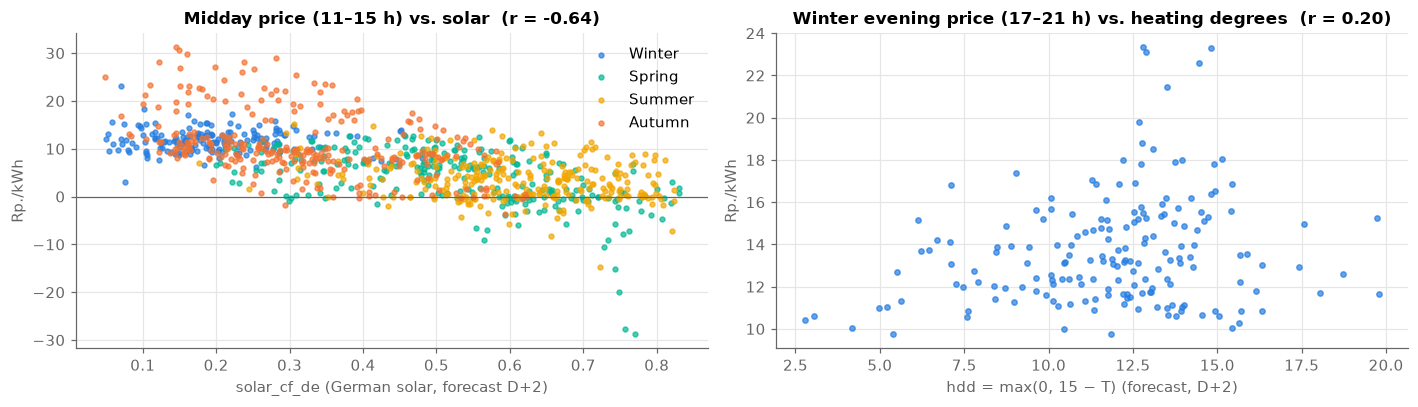

Midday price vs. solar: Germany r = -0.64, Switzerland r = -0.63


In [8]:
# Only hours with a known price
labelled = data[data["price_rp_kwh"].notna()]
per_day = labelled.groupby("date")

# Midday (11-14 h) per day: average price and solar forecast
midday = labelled[labelled["hour"].between(11, 14)].groupby("date").agg(
    price=("price_rp_kwh", "mean"), solar=("solar_cf_de_d2", "mean"), solar_ch=("solar_cf_ch_d2", "mean"))
midday["season"] = midday.index.month.map(SEASONS)

# Winter evenings (17-20 h, December to February): average price and heating degrees
winter = labelled[labelled["hour"].between(17, 20) & labelled["date"].dt.month.isin([12, 1, 2])]
evening = winter.groupby("date").agg(price=("price_rp_kwh", "mean"), hdd=("hdd_d2", "mean"))

# Left: midday price vs. solar, coloured by season. Right: winter evening price vs. hdd
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for season, colour in SEASON_COLOURS.items():
    part = midday[midday["season"] == season]
    axes[0].scatter(part["solar"], part["price"], s=10, color=colour, alpha=0.7, label=season)
axes[0].axhline(0, color=GREY, linewidth=0.8)
axes[0].set(title=f"Midday price (11–15 h) vs. solar  (r = {midday['solar'].corr(midday['price']):.2f})",
            xlabel="solar_cf_de (German solar, forecast D+2)", ylabel="Rp./kWh")
axes[0].legend(frameon=False)
axes[1].scatter(evening["hdd"], evening["price"], s=12, color=BLUE, alpha=0.7)
axes[1].set(title=f"Winter evening price (17–21 h) vs. heating degrees  (r = {evening['hdd'].corr(evening['price']):.2f})",
            xlabel="hdd = max(0, 15 − T) (forecast, D+2)", ylabel="Rp./kWh")
plt.tight_layout()
plt.show()

print(f"Midday price vs. solar: Germany r = {midday['solar'].corr(midday['price']):.2f}, "
      f"Switzerland r = {midday['solar_ch'].corr(midday['price']):.2f}")

**Finding:** Solar drives the midday price strongly, German and Swiss almost equally (r = −0.64 and −0.63, the two are highly correlated); negative midday prices occur almost only when German solar is above 0.5. Temperature shows only a weak link to the winter evening price level (r = 0.20); expect `hdd` to play a minor role, at most as a change (`d_hdd`).

## 6 · Forecast quality by lead time

Forecast made 1, 2 and 3 days ahead vs. the measured value, as mean absolute error.
The model for D+3 has to live with the larger error.

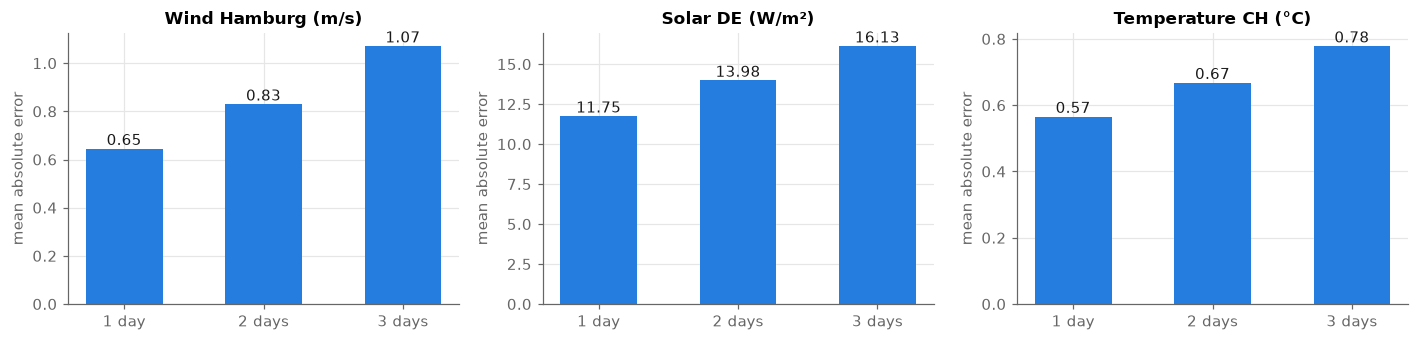

In [9]:
# Weather variables to check: chart label -> column name
variables = {"Wind Hamburg (m/s)": "wind_de_hamburg", "Solar DE (W/m²)": "solar_de",
             "Temperature CH (°C)": "temperature"}
# Only hours with a measured value (not just a forecast)
check = labelled[labelled["is_forecast"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (label, column) in zip(axes, variables.items()):
    # Mean absolute error of the forecast made 1, 2 and 3 days ahead
    errors = [(check[f"{column}_fc_d{k}"] - check[column]).abs().mean() for k in (1, 2, 3)]
    ax.bar(["1 day", "2 days", "3 days"], errors, color=BLUE, width=0.55)
    # Write the value above each bar
    for x, e in enumerate(errors):
        ax.text(x, e, f"{e:.2f}", ha="center", va="bottom", color="#191919")
    ax.set(title=label, ylabel="mean absolute error")
plt.tight_layout()
plt.show()

**Finding:** Forecast errors grow steadily with lead time: from 1 to 3 days ahead by about 65 % for wind (0.65 → 1.07 m/s) and about 37 % for solar and temperature. The D+3 model gets noisier inputs and will likely be less accurate than the D+2 model.

## 7 · Where are the savings?

Two decisions a charging plan makes:
- **Which hours within a night:** average price of the window vs. its cheapest 4 hours.
- **Which night:** difference of the cheapest-4-hours price between consecutive nights.

Whichever is larger is where the model has to be good.

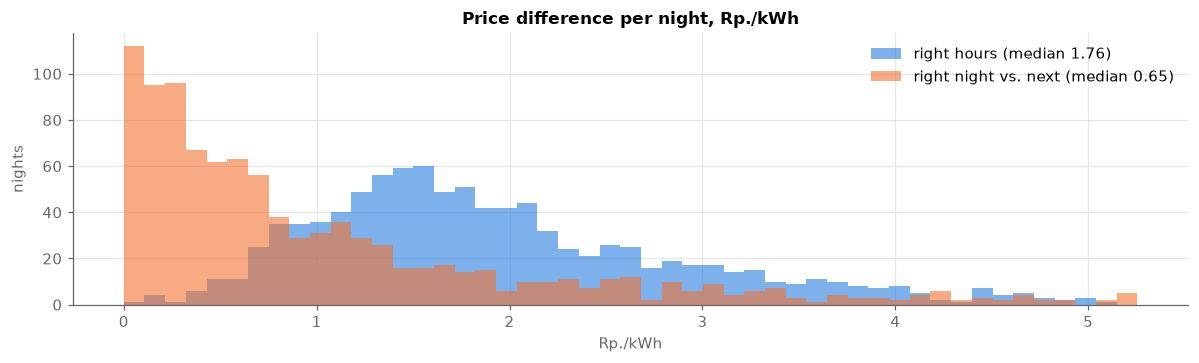

Right hours within a night:      mean 2.00, median 1.76 Rp./kWh
Right night (vs. next night):     mean 1.11, median 0.65 Rp./kWh
Tonight vs. best of next 3:       mean 0.97 Rp./kWh, tonight is already the cheapest in 37% of cases


In [10]:
# Per night: average of the 4 cheapest hours (what a smart charging plan pays)
cheapest4 = nights.groupby("night")["price_rp_kwh"].apply(lambda p: p.nsmallest(4).mean())
# Per night: average over all depot hours (what charging at random hours pays)
window_mean = nights.groupby("night")["price_rp_kwh"].mean()
# Only complete nights (at least 12 hours)
full = nights.groupby("night").size() >= 12
cheapest4, window_mean = cheapest4[full], window_mean[full]

within = window_mean - cheapest4                    # gain from picking the right hours
between = cheapest4.diff().abs().dropna()           # gain from picking the right night (vs. the next)
best_of_3 = cheapest4 - cheapest4[::-1].rolling(3, min_periods=3).min()[::-1]  # tonight vs. best of next 3

fig, ax = plt.subplots(figsize=(11, 3.4))
# Same bins for both histograms, up to the 98th percentile (cuts off a few outliers)
bins = np.linspace(0, np.percentile(pd.concat([within, between, best_of_3.dropna()]), 98), 50)
ax.hist(within, bins=bins, color=BLUE, alpha=0.6, label=f"right hours (median {within.median():.2f})")
ax.hist(between, bins=bins, color=ORANGE, alpha=0.6, label=f"right night vs. next (median {between.median():.2f})")
ax.set(title="Price difference per night, Rp./kWh", xlabel="Rp./kWh", ylabel="nights")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Right hours within a night:      mean {within.mean():.2f}, median {within.median():.2f} Rp./kWh")
print(f"Right night (vs. next night):     mean {between.mean():.2f}, median {between.median():.2f} Rp./kWh")
print(f"Tonight vs. best of next 3:       mean {best_of_3.mean():.2f} Rp./kWh, "
      f"tonight is already the cheapest in {(best_of_3 == 0).mean():.0%} of cases")

**Finding:** Over the fleet's depot hours (16:00–08:00), picking the right hours within a night is worth more (median 1.76 Rp./kWh) than picking the right night (median 0.65 vs. the next night), but the night choice is skewed: usually small, sometimes above 2 Rp./kWh. Tonight is already the cheapest of the next three nights in only 37 % of cases. Important: tonight's and tomorrow's prices are **known**, so the within-night gain needs no model. The model's value lies in deciding whether to wait for a later night, which is why the level metrics (cheapest-4-hours MAE, sign accuracy) matter most.

## 8 · The simple rules to beat

On the local-time grid, for issue date D: the known day is D+1.
- **Copy of D+1:** price of D+h = price of D+1, hour by hour.
- **Last week:** price of D+h = price 7 days earlier.

In [11]:
# MAE of the two simple rules for D+2 and D+3, over all hours and over the depot hours only
rows = []
# Hours in which the fleet is in the depot (from evening arrival to morning departure)
window_hours = [h for h in range(24) if h >= arrival or h < departure]
for h in (2, 3):
    copy = price_ch.shift(h - 1)        # D+1 is h-1 days before the target day D+h
    week = price_ch.shift(7)
    for name, guess in [("Copy of D+1", copy), ("Last week", week)]:
        # Absolute error per hour
        error = (price_ch - guess).abs()
        rows.append({"horizon": f"D+{h}", "rule": name,
                     "MAE all hours": error.stack().mean(),
                     "MAE depot hours": error[window_hours].stack().mean()})
# Table with one row per (horizon, rule)
rules = pd.DataFrame(rows).set_index(["horizon", "rule"]).round(2)
rules

MAE all hours  MAE depot hours
horizon rule                                       
D+2     Copy of D+1           1.68             1.24
        Last week             1.97             1.62
D+3     Copy of D+1           2.29             1.62
        Last week             1.97             1.62

**Finding:** For D+2, copying D+1 clearly beats last week (MAE 1.68 vs. 1.97 on all hours, 1.24 vs. 1.62 in the depot hours). For D+3, last week wins on all hours (1.97 vs. 2.29), and in the depot hours both are equal (1.62 vs. 1.62). The model has to beat about 1.24 (D+2) and 1.62 (D+3) Rp./kWh in the depot hours.

## Summary

- **Data quality:** 995 complete days (9 Mar 2024 to 28 Nov 2026), exactly 24 hours each after the clock-change fix, no gaps.
- **Target:** mostly 0.5–20 Rp./kWh with 3.5 % negative hours (spring/summer, midday). The level has risen sharply since September 2026, so the model should predict changes vs. the known day, as planned.
- **Drivers:** solar is the strongest weather driver (midday, r ≈ −0.64 for German and Swiss alike); wind matters for *changes* between nights (r = −0.47, weaker in winter); temperature is weak. DE prices track CH closely but not perfectly.
- **Forecast inputs:** errors grow by roughly 40–65 % from 1 to 3 days ahead, so D+3 will be harder than D+2.
- **Where the money is:** the within-night gain is available without a model (prices known); the model has to get the **night choice** right, so level and sign metrics decide.
- **Bar to beat (fleet depot hours 16:00–08:00):** about 1.24 Rp./kWh for D+2 (copy of D+1) and 1.62 for D+3.